<a href="https://colab.research.google.com/github/jsmak/dl-framework/blob/main/08_multi_io_model/08_multi_io_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **8강 PyTorch로 만드는 비순차 모델: 다중 입력과 다중 출력**
- 6강의 캘리포니아 집값 모델을 입력 두 개, 출력 두 개인 비순차 구조로 확장하기.

6강에서는 특성 8개를 한 줄로 넣어 집값 하나를 예측하는 **순차 모델**을 만들었습니다.  
실무에서는 형태가 다른 여러 입력을 함께 쓰거나, 하나의 입력으로 여러 값을 동시에 예측해야 할 때가 많습니다.  
이번에는 같은 데이터로 입력 경로를 둘로 나누고, 집값(회귀)과 고가 주택 여부(분류)를 함께 예측하는 모델을 만들어 봅니다.  
데이터가 작아서 성능 차이를 보기보다는, 실무에서 쓸 수 있는 구조를 맛보는 것이 목적입니다.  

1. **Wide & Deep 구조 응용**: 2016년 구글 연구진(Heng-Tze Cheng 등)이 발표한 구조로, 입력의 일부는 깊은 경로로, 일부는 출력 쪽에 바로 연결해 두 경로의 결과를 함께 사용
2. **잔차 연결(Residual Connection)**: 7강에서 본 것처럼 기울기 소실을 완화하는 `x + F(x)` 블록
3. **다중 입력 Dataset**: 입력 두 개와 정답 두 개를 함께 돌려주는 커스텀 데이터셋
4. **다중 출력(Multi-Task)**: 회귀(집값 예측)와 분류(고가 주택 판별)를 동시에 수행
5. **다중 손실**: 두 손실을 가중합해 하나의 총손실로 역전파
6. 모델 평가와 **계산 그래프** 시각화

## **1. 실습 준비**

계산 그래프를 그리기 위해 `torchviz`를 설치합니다.  
방화벽 등으로 데이터를 내려받을 수 없는 주피터 노트북 환경에서는 이 셀의 `wget` 줄의 주석을 해제해 내려받거나,  
`cal_housing_py3.pkz`를 노트북과 같은 폴더에 직접 복사하세요. 그런 다음 다음 셀의 데이터 로드 줄을 바꿔 실행합니다.

In [1]:
%pip install -q torchviz
#!wget -q -nc https://raw.githubusercontent.com/jsmak/dl-framework/main/06_mlp_regression/cal_housing_py3.pkz

## **2. 라이브러리 임포트와 데이터 로드**

6강과 같은 캘리포니아 주택 가격 데이터를 불러오고, 두 가지를 새로 준비합니다.

- **분류 정답**: 집값이 2.0(20만 달러) 이상이면 고가 주택(1), 아니면 0
- **입력 나누기**: 앞의 6개 특성(소득, 주택 연식, 방 개수 등)은 Deep 입력, 위도와 경도 2개는 Wide 입력

In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 재현성을 위한 시드
np.random.seed(42)
torch.manual_seed(42)

# 데이터 로드
housing = fetch_california_housing() # 방화벽 등으로 데이터를 받을 수 없으면 이 줄을 주석 처리하고 아래 줄을 실행하세요.
# housing = fetch_california_housing(data_home='./', download_if_missing=False)

X = housing.data
y_reg = housing.target.reshape(-1, 1)

# 분류 타겟 생성: 집값이 2.0 이상이면 고가 주택(1), 아니면(0)
y_cls = (y_reg >= 2.0).astype(np.float32)

# 입력 특성 분리
# Deep 입력 (0~5번 컬럼): MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup
X_deep = X[:, :6]
# Wide 입력 (6~7번 컬럼): Latitude, Longitude
X_wide = X[:, 6:]

print("X_deep shape:", X_deep.shape)
print("X_wide shape:", X_wide.shape)
print("y_reg shape:", y_reg.shape)
print("y_cls shape:", y_cls.shape)
print("특성 이름:", housing.feature_names)

X_deep shape: (20640, 6)
X_wide shape: (20640, 2)
y_reg shape: (20640, 1)
y_cls shape: (20640, 1)
특성 이름: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


## **3. 데이터 분할과 표준화**

두 입력과 두 정답을 같은 기준으로 훈련 세트와 테스트 세트로 나눕니다.
표준화는 입력마다 따로 하고, 기준은 훈련 데이터에서만 구한 뒤 테스트 데이터에 그대로 적용합니다. 그런 다음 텐서로 변환합니다.

In [3]:
X_deep_train, X_deep_test, X_wide_train, X_wide_test, y_reg_train, y_reg_test, y_cls_train, y_cls_test = train_test_split(
    X_deep, X_wide, y_reg, y_cls, test_size=0.2, random_state=42
)

scaler_deep = StandardScaler()
scaler_wide = StandardScaler()

X_deep_train = scaler_deep.fit_transform(X_deep_train)
X_deep_test = scaler_deep.transform(X_deep_test)

X_wide_train = scaler_wide.fit_transform(X_wide_train)
X_wide_test = scaler_wide.transform(X_wide_test)

# PyTorch 텐서 변환
X_deep_train = torch.tensor(X_deep_train, dtype=torch.float32)
X_deep_test = torch.tensor(X_deep_test, dtype=torch.float32)

X_wide_train = torch.tensor(X_wide_train, dtype=torch.float32)
X_wide_test = torch.tensor(X_wide_test, dtype=torch.float32)

y_reg_train = torch.tensor(y_reg_train, dtype=torch.float32)
y_reg_test = torch.tensor(y_reg_test, dtype=torch.float32)

y_cls_train = torch.tensor(y_cls_train, dtype=torch.float32)
y_cls_test = torch.tensor(y_cls_test, dtype=torch.float32)

print("Deep 학습 데이터:", X_deep_train.shape)
print("Wide 학습 데이터:", X_wide_train.shape)

Deep 학습 데이터: torch.Size([16512, 6])
Wide 학습 데이터: torch.Size([16512, 2])


## **4. 다중 입력 Dataset과 DataLoader**

6강의 데이터셋은 `(X, y)` 두 개를 돌려주었습니다.
이번에는 `__getitem__`이 입력 두 개(`X_deep`, `X_wide`)와 정답 두 개(`y_reg`, `y_cls`)를 함께 돌려줍니다.
DataLoader는 6강과 같이 배치 크기 64로 묶습니다.

In [4]:
from torch.utils.data import Dataset, DataLoader

class MultiTaskHousingDataset(Dataset):
    def __init__(self, X_deep, X_wide, y_reg, y_cls):
        self.X_deep = X_deep
        self.X_wide = X_wide
        self.y_reg = y_reg
        self.y_cls = y_cls

    def __len__(self):
        return len(self.X_deep)

    def __getitem__(self, idx):
        return self.X_deep[idx], self.X_wide[idx], self.y_reg[idx], self.y_cls[idx]

train_dataset = MultiTaskHousingDataset(X_deep_train, X_wide_train, y_reg_train, y_cls_train)
test_dataset = MultiTaskHousingDataset(X_deep_test, X_wide_test, y_reg_test, y_cls_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print("학습 배치 수:", len(train_loader))

학습 배치 수: 258


## **5. 모델 설계: Wide & Deep + 잔차 연결 + 두 개의 출력**

- **잔차 블록**: `x + layer(x)`로 입력을 출력에 더합니다. 원소별 덧셈이라 입력과 출력의 크기가 같아야 합니다.
- **Deep 경로**: 6개 특성을 잔차 블록 두 개에 통과시킵니다. 크기는 6 그대로 유지됩니다.
- **Wide 경로**: 위도·경도 2개를 선형 층 하나로 4개 값으로 바꿉니다.
- **결합**: `torch.cat`으로 두 경로를 이어 붙여(6 + 4 = 10) 공유 잔차 블록에 통과시킵니다.
- **두 개의 헤드**: 회귀 헤드는 집값을, 분류 헤드는 시그모이드 전의 값(로짓)을 출력합니다.

손실 함수는 회귀에 `MSELoss`, 분류에 `BCEWithLogitsLoss`를 사용합니다. `BCEWithLogitsLoss`는 시그모이드와 이진 교차 엔트로피를 한 번에 계산합니다.

In [5]:
class ResidualBlock(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.layer = nn.Sequential(
            nn.Linear(input_dim, input_dim*4),
            nn.ReLU(),
            nn.Linear(input_dim*4, input_dim)
        )
        self.activation = nn.ReLU()

    def forward(self, x):
        return self.activation(x + self.layer(x))

class WideDeepMultiTaskResNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        # Residual Blocks
        self.res_block1 = ResidualBlock(6)
        self.res_block2 = ResidualBlock(6)
        
        # Wide 파트 (입력: 2개 지리적 특성)
        self.wide_layer = nn.Linear(2, 4)
        
        # 병합 후 크기: Deep 출력 6 + Wide 출력 4 = 10       
        self.res_block3 = ResidualBlock(10)        
        self.reg_head = nn.Linear(10, 1)  # 회귀용 헤드 (집값 예측)        
        self.cls_head = nn.Linear(10, 1)  # 분류용 헤드 (고가 주택 확률 로짓)

    def forward(self, x_deep, x_wide):
        # 1. Deep 경로 순전파
        deep_out = self.res_block1(x_deep)
        deep_out = self.res_block2(deep_out)
                
        # 2. Wide 경로 순전파
        wide_out = self.wide_layer(x_wide)
        
        # 3. 특성 결합 (Concatenation)
        combined = torch.cat((deep_out, wide_out), dim=1)
        combined = self.res_block3(combined)
        
        # 4. 멀티태스크 출력 계산
        reg_out = self.reg_head(combined)
        cls_out = self.cls_head(combined)
        return reg_out, cls_out

model = WideDeepMultiTaskResNet()

# 회귀용 Loss (MSE)와 분류용 Loss (BCEWithLogits)
criterion_reg = nn.MSELoss()
criterion_cls = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)
print("\n=== Model Parameters ===")
for name, param in model.named_parameters():
    print(f"Parameter: {name:<20} | Shape: {str(param.shape):<20} | Requires Grad: {param.requires_grad}")

WideDeepMultiTaskResNet(
  (res_block1): ResidualBlock(
    (layer): Sequential(
      (0): Linear(in_features=6, out_features=24, bias=True)
      (1): ReLU()
      (2): Linear(in_features=24, out_features=6, bias=True)
    )
    (activation): ReLU()
  )
  (res_block2): ResidualBlock(
    (layer): Sequential(
      (0): Linear(in_features=6, out_features=24, bias=True)
      (1): ReLU()
      (2): Linear(in_features=24, out_features=6, bias=True)
    )
    (activation): ReLU()
  )
  (wide_layer): Linear(in_features=2, out_features=4, bias=True)
  (res_block3): ResidualBlock(
    (layer): Sequential(
      (0): Linear(in_features=10, out_features=40, bias=True)
      (1): ReLU()
      (2): Linear(in_features=40, out_features=10, bias=True)
    )
    (activation): ReLU()
  )
  (reg_head): Linear(in_features=10, out_features=1, bias=True)
  (cls_head): Linear(in_features=10, out_features=1, bias=True)
)

=== Model Parameters ===
Parameter: res_block1.layer.0.weight | Shape: torch.Size([2

## **6. 학습 루프: 두 손실의 가중합**

학습 루프는 6강과 같은 5단계입니다. 달라진 것은 손실 계산뿐입니다.
회귀 손실과 분류 손실을 각각 구한 뒤 `alpha`, `beta`로 가중합해 하나의 총손실을 만들고, 이 총손실 하나로 역전파합니다.

1. `optimizer.zero_grad()` : 기울기 초기화
2. `model(X_deep, X_wide)` : 순전파로 두 예측값 계산
3. `loss = alpha * loss_reg + beta * loss_cls` : 두 손실 계산과 가중합
4. `loss.backward()` : 역전파
5. `optimizer.step()` : 파라미터 업데이트

In [6]:
epochs = 20
alpha = 0.5  # 회귀 손실 가중치
beta = 0.5   # 분류 손실 가중치

train_losses = []
test_losses = []

for epoch in range(epochs):
    # --- Training ---
    model.train()
    total_train_loss = 0.0
    
    for batch_x_deep, batch_x_wide, batch_y_reg, batch_y_cls in train_loader:
        optimizer.zero_grad()                                # 1. 기존 기울기 초기화
        
        pred_reg, pred_cls = model(batch_x_deep, batch_x_wide) # 2. 순전파
        
        loss_reg = criterion_reg(pred_reg, batch_y_reg)      # 3. 손실 계산
        loss_cls = criterion_cls(pred_cls, batch_y_cls)
        loss = (alpha * loss_reg) + (beta * loss_cls)        # 가중합을 통한 최종 Loss 도출
        
        loss.backward()                                      # 4. 역전파
        optimizer.step()                                     # 5. 파라미터 업데이트

        total_train_loss += loss.item() * len(batch_y_reg)
        
    avg_train_loss = total_train_loss / len(train_dataset)
    train_losses.append(avg_train_loss)

    # --- Evaluation ---
    model.eval()
    total_test_loss = 0.0
    with torch.no_grad():
        for batch_x_deep, batch_x_wide, batch_y_reg, batch_y_cls in test_loader:
            test_pred_reg, test_pred_cls = model(batch_x_deep, batch_x_wide)
            
            t_loss_reg = criterion_reg(test_pred_reg, batch_y_reg)
            t_loss_cls = criterion_cls(test_pred_cls, batch_y_cls)
            t_loss = (alpha * t_loss_reg) + (beta * t_loss_cls)
            
            total_test_loss += t_loss.item() * len(batch_y_reg)
            
    avg_test_loss = total_test_loss / len(test_dataset)
    test_losses.append(avg_test_loss)

    print(f"Epoch {epoch + 1:02d} | Train Total Loss: {avg_train_loss:.4f} | Test Total Loss: {avg_test_loss:.4f}")

Epoch 01 | Train Total Loss: 0.8336 | Test Total Loss: 0.5805
Epoch 02 | Train Total Loss: 0.4946 | Test Total Loss: 0.4256
Epoch 03 | Train Total Loss: 0.3927 | Test Total Loss: 0.3773
Epoch 04 | Train Total Loss: 0.3639 | Test Total Loss: 0.3573
Epoch 05 | Train Total Loss: 0.3502 | Test Total Loss: 0.3465
Epoch 06 | Train Total Loss: 0.3412 | Test Total Loss: 0.3398
Epoch 07 | Train Total Loss: 0.3348 | Test Total Loss: 0.3365
Epoch 08 | Train Total Loss: 0.3278 | Test Total Loss: 0.3281
Epoch 09 | Train Total Loss: 0.3237 | Test Total Loss: 0.3251
Epoch 10 | Train Total Loss: 0.3214 | Test Total Loss: 0.3184
Epoch 11 | Train Total Loss: 0.3145 | Test Total Loss: 0.3163
Epoch 12 | Train Total Loss: 0.3131 | Test Total Loss: 0.3130
Epoch 13 | Train Total Loss: 0.3061 | Test Total Loss: 0.3067
Epoch 14 | Train Total Loss: 0.3037 | Test Total Loss: 0.3100
Epoch 15 | Train Total Loss: 0.3009 | Test Total Loss: 0.2997
Epoch 16 | Train Total Loss: 0.2972 | Test Total Loss: 0.2999
Epoch 17

Epoch 02 | Train Total Loss: 0.4946 | Test Total Loss: 0.4256


Epoch 03 | Train Total Loss: 0.3927 | Test Total Loss: 0.3773


Epoch 04 | Train Total Loss: 0.3639 | Test Total Loss: 0.3573


Epoch 05 | Train Total Loss: 0.3502 | Test Total Loss: 0.3465


Epoch 06 | Train Total Loss: 0.3412 | Test Total Loss: 0.3398


... (10 outputs left out)

Epoch 17 | Train Total Loss: 0.2954 | Test Total Loss: 0.3017


Epoch 18 | Train Total Loss: 0.2935 | Test Total Loss: 0.2959


Epoch 19 | Train Total Loss: 0.2922 | Test Total Loss: 0.2922


Epoch 20 | Train Total Loss: 0.2915 | Test Total Loss: 0.2905


## **7. 학습 곡선**

에폭마다 기록한 훈련 총손실과 테스트 총손실을 그려, 두 손실이 함께 줄어드는지 확인합니다.

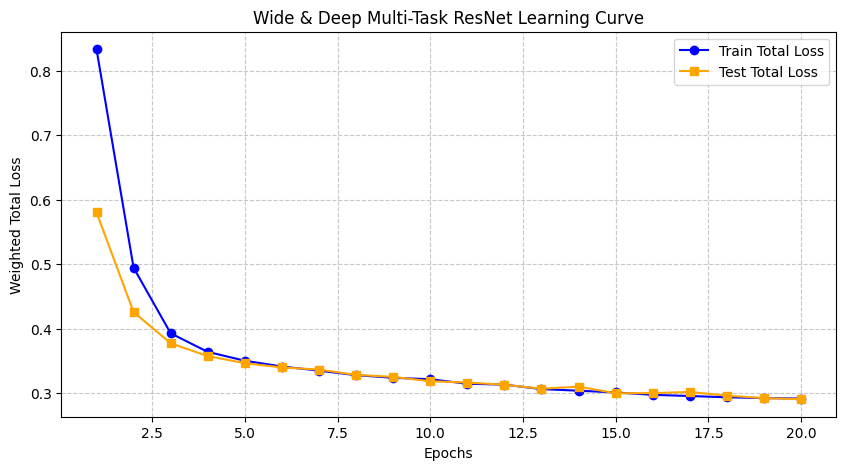

In [7]:
epochs_range = range(1, epochs + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_range, train_losses, label='Train Total Loss', color='blue', marker='o')
plt.plot(epochs_range, test_losses, label='Test Total Loss', color='orange', marker='s')

plt.title('Wide & Deep Multi-Task ResNet Learning Curve')
plt.xlabel('Epochs')
plt.ylabel('Weighted Total Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## **8. 최종 평가**

테스트 데이터로 두 출력을 각각 평가합니다.
- 회귀: MSE와 RMSE
- 분류: 로짓에 시그모이드를 적용해 확률로 바꾼 뒤, 0.5 이상이면 고가 주택으로 판단해 정확도 계산

In [8]:
model.eval()
squared_error = 0.0
correct_predictions = 0

with torch.no_grad():
    for batch_x_deep, batch_x_wide, batch_y_reg, batch_y_cls in test_loader:
        pred_reg, pred_cls = model(batch_x_deep, batch_x_wide)
        
        # 회귀 오차 누적
        squared_error += ((pred_reg - batch_y_reg).square().sum().item())
        
        # 분류 정확도 계산 (Logit을 확률로 변환 후 0.5 임계값 적용)
        probs = torch.sigmoid(pred_cls)
        predicted_classes = (probs >= 0.5).float()
        correct_predictions += (predicted_classes == batch_y_cls).sum().item()

test_mse = squared_error / len(test_dataset)
test_rmse = test_mse ** 0.5
test_accuracy = correct_predictions / len(test_dataset) * 100

print(f"=== Test Set Evaluation ===")
print(f"Regression MSE:  {test_mse:.4f}")
print(f"Regression RMSE: {test_rmse:.4f}")
print(f"Classification Accuracy: {test_accuracy:.2f}%")

=== Test Set Evaluation ===
Regression MSE:  0.2879
Regression RMSE: 0.5365
Classification Accuracy: 87.33%


## **9. 다중 손실 계산 그래프 출력**

총손실에서 출발하는 계산 그래프를 확인합니다.
그래프 위쪽에서 두 손실이 더해지는 지점과, 잔차 블록마다 입력과 층의 출력이 더해지는 `AddBackward` 노드를 찾아보세요.
역전파 때 덧셈 노드는 받은 기울기를 양쪽에 그대로 전달하고, 공유 블록에서는 두 헤드에서 온 기울기가 합쳐집니다.

- 초록색: 손실 (출발점)
- 회색: 역전파 때 기울기를 전달하는 연산 노드
- 파란색: 학습할 파라미터 (도착점)

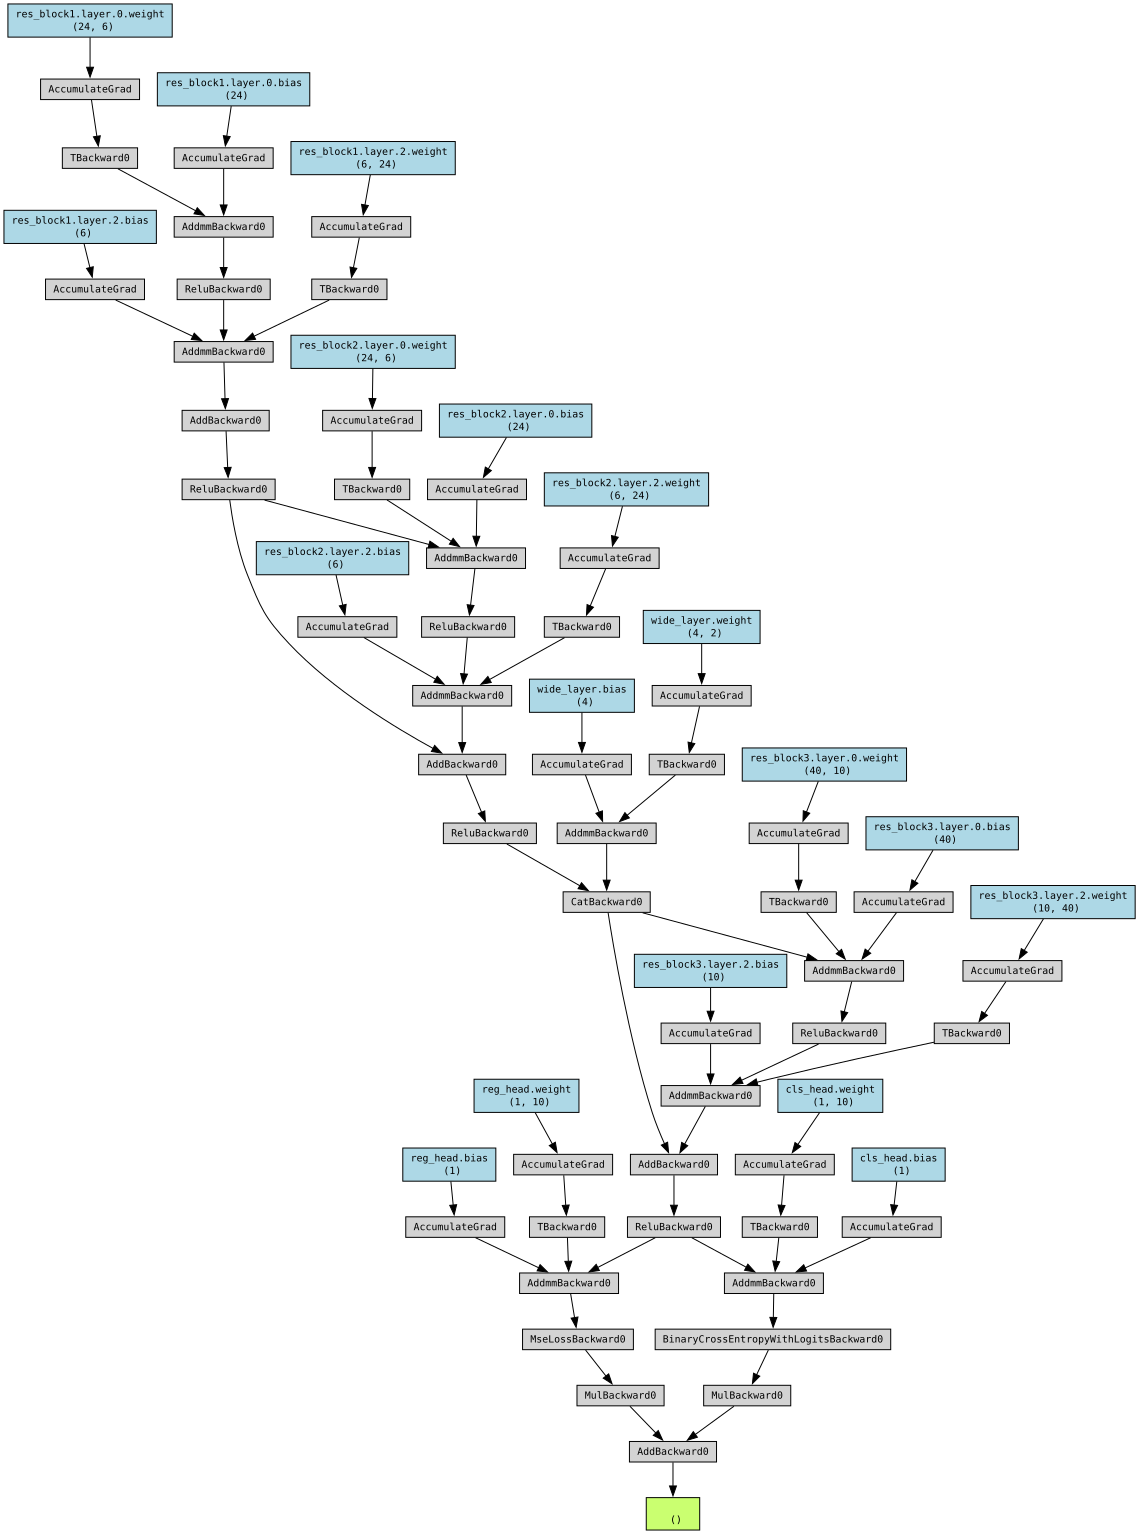

In [9]:
from torchviz import make_dot
from IPython.display import display, Image

model.eval()

batch_x_deep, batch_x_wide, batch_y_reg, batch_y_cls = next(iter(train_loader))

# 계산 수행
pred_reg, pred_cls = model(batch_x_deep, batch_x_wide)
loss_reg = criterion_reg(pred_reg, batch_y_reg)
loss_cls = criterion_cls(pred_cls, batch_y_cls)
loss = (alpha * loss_reg) + (beta * loss_cls) # 가중합된 최종 손실

# 손실에서 역방향으로 연결된 계산 그래프 시각화
dot = make_dot(
    loss,
    params=dict(model.named_parameters())
)

# 코랩 환경에서 표시
display(dot)